In [55]:
import pandas as pd
import torch
import numpy as np

In [56]:
train_data = pd.read_csv("data/logistic_growth_train.csv")
test_data = pd.read_csv("data/logistic_growth_test.csv")

In [57]:
train_data.head()

,L0_initial,growth_rate_a,competition_coeff_b,t_grid_0,t_grid_1,t_grid_2,t_grid_3,t_grid_4,t_grid_5,t_grid_6,...,L_t90,L_t91,L_t92,L_t93,L_t94,L_t95,L_t96,L_t97,L_t98,L_t99
0,33.090710,0.371776,0.009158,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,40.593517,40.587255,40.581092,40.575867,40.572564,40.572313,40.575604,40.578874,40.581583,40.583828
1,47.129551,0.453238,0.001284,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,352.809044,352.843019,352.868486,352.884291,352.890521,352.888510,352.880828,352.871294,352.864964,352.868141
2,19.639865,0.197991,0.001407,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,140.603070,140.609302,140.615048,140.620868,140.627370,140.635091,140.642624,140.649441,140.655610,140.661192
3,30.488209,0.459523,0.003674,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,125.033383,125.044394,125.053031,125.058881,125.061897,125.062401,125.061080,125.058988,125.057546,125.058541
4,47.760681,0.558657,0.002231,0.0,0.505051,1.010101,1.515152,2.020202,2.525253,3.030303,...,250.454216,250.461245,250.448120,250.416163,250.369764,250.316377,250.266520,250.233778,250.234799,250.265873


In [58]:
train_data.columns

Index(['L0_initial', 'growth_rate_a', 'competition_coeff_b', 't_grid_0',
       't_grid_1', 't_grid_2', 't_grid_3', 't_grid_4', 't_grid_5', 't_grid_6',
       ...
       'L_t90', 'L_t91', 'L_t92', 'L_t93', 'L_t94', 'L_t95', 'L_t96', 'L_t97',
       'L_t98', 'L_t99'],
      dtype='object', length=203)

In [59]:
params = train_data[['L0_initial', 'growth_rate_a', 'competition_coeff_b']].values

trajectories = train_data.filter(regex='L_t').values

x_data = torch.tensor(params, dtype=torch.float32)
y_data = torch.tensor(trajectories, dtype=torch.float32)

#Reshape for Neural Operator (Batch, Channels, Length)
x_data = x_data.unsqueeze(1) # Becomes (N, 1, 3)
y_data = y_data.unsqueeze(1) # Becomes (N, 1, 100)

print(f"Input shape: {x_data.shape}")  # e.g., torch.Size([1000, 1, 3])
print(f"Target shape: {y_data.shape}") # e.g., torch.Size([1000, 1, 100])

Input shape: torch.Size([400, 1, 3])
Target shape: torch.Size([400, 1, 100])


In [60]:
import torch
from sklearn.preprocessing import StandardScaler

# Inicjalizacja i dopasowanie skalera (bez zmian)
scaler = StandardScaler()
scaler.fit(train_data[['L0_initial', 'growth_rate_a', 'competition_coeff_b']])

def prepare_logistic_data(df, scaler):
    p_cols = ['L0_initial', 'growth_rate_a', 'competition_coeff_b']
    scaled_params = scaler.transform(df[p_cols])
    x_params = torch.tensor(scaled_params, dtype=torch.float32) # [N, 3]
    
    t_cols = [c for c in df.columns if c.startswith('t_grid_')]
    # Wyciągamy wartości t_grid i dodajemy wymiar kanału: [N, 100] -> [N, 1, 100]
    grid = torch.tensor(df[t_cols].values, dtype=torch.float32).unsqueeze(1)
    
    # Trajektoria
    y_cols = [c for c in df.columns if c.startswith('L_t')]
    y = torch.tensor(df[y_cols].values, dtype=torch.float32).unsqueeze(1) # [N, 1, 100]
    
    # 4. Rozszerzenie parametrów do wymiaru siatki (N, 3) -> (N, 3, 100)
    num_steps = len(t_cols)
    x_expanded = x_params.unsqueeze(-1).repeat(1, 1, num_steps)
    
    # 5. Łączenie: [3 kanały parametrów] + [1 kanał siatki z CSV]
    # Wynik: (N, 4, 100)
    x = torch.cat([x_expanded, grid], dim=1)
    
    return x, y

# Użycie funkcji pozostaje takie samo
x_train, y_train = prepare_logistic_data(train_data, scaler)
x_test, y_test = prepare_logistic_data(test_data, scaler)

In [61]:
from neuralop.models import FNO

In [62]:
operator = FNO(
    n_modes=(32,),  
    hidden_channels=128,
    in_channels=4,
    out_channels=1
)

In [63]:
test_input = torch.randn(32, 4, 100) 
output = operator(test_input)

print(f"Input Shape: {test_input.shape}")   # [32, 4, 100]
print(f"Output Shape: {output.shape}")

Input Shape: torch.Size([32, 4, 100])
Output Shape: torch.Size([32, 1, 100])


In [64]:
from torch.utils.data import DataLoader, TensorDataset

# Create datasets
train_dataset = TensorDataset(x_train, y_train)
test_dataset = TensorDataset(x_test, y_test)

# Create loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [65]:
print(x_train.shape) # ma wyjść [400, 4, 100]


torch.Size([400, 4, 100])


In [72]:
import torch.optim as optim
import torch.nn.functional as F

# Inicjalizacja list na historię
train_losses = []
val_losses = []

optimizer = optim.Adam(operator.parameters(), lr=1e-3)
criterion = torch.nn.MSELoss()

epochs = 20

for epoch in range(epochs):
    operator.train()
    total_loss = 0
    
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        output = operator(batch_x)
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_train_loss = total_loss / len(train_loader)
    train_losses.append(avg_train_loss) 
    
    total_val_loss = 0
    with torch.no_grad():
        for val_batch_x, val_batch_y in test_loader:
            val_output = operator(val_batch_x)
            v_loss = criterion(val_output, val_batch_y)
            total_val_loss += v_loss.item()
            
    avg_val_loss = total_val_loss / len(test_loader)
    val_losses.append(avg_val_loss) # Zapisujemy do listy
        
    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.6f} | Val Loss: {avg_val_loss:.6f}")


Epoch [1/20] | Train Loss: 2166.156954 | Val Loss: 987.029770
Epoch [2/20] | Train Loss: 653.390229 | Val Loss: 581.325365
Epoch [3/20] | Train Loss: 249.904300 | Val Loss: 290.033856
Epoch [4/20] | Train Loss: 131.783812 | Val Loss: 156.689827
Epoch [5/20] | Train Loss: 83.724600 | Val Loss: 82.849639
Epoch [6/20] | Train Loss: 72.651046 | Val Loss: 120.248360
Epoch [7/20] | Train Loss: 63.793691 | Val Loss: 71.696043
Epoch [8/20] | Train Loss: 56.448819 | Val Loss: 77.043308
Epoch [9/20] | Train Loss: 84.178256 | Val Loss: 146.632854
Epoch [10/20] | Train Loss: 68.428066 | Val Loss: 52.895823
Epoch [11/20] | Train Loss: 48.652614 | Val Loss: 65.649815
Epoch [12/20] | Train Loss: 41.739138 | Val Loss: 55.263821
Epoch [13/20] | Train Loss: 95.884540 | Val Loss: 75.020074
Epoch [14/20] | Train Loss: 71.732740 | Val Loss: 190.704806
Epoch [15/20] | Train Loss: 88.771352 | Val Loss: 180.315330
Epoch [16/20] | Train Loss: 82.441844 | Val Loss: 97.647590
Epoch [17/20] | Train Loss: 67.34724

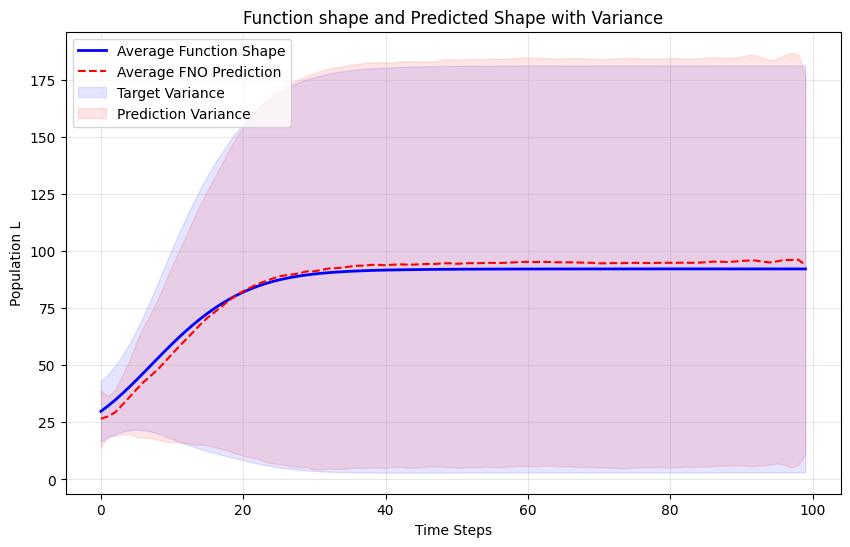

In [73]:
import numpy as np
import matplotlib.pyplot as plt
operator.eval()
with torch.no_grad():
    # 1. Get all predictions for the test set
    # Shape: [N_test, 1, 100]
    all_preds = operator(x_test).squeeze().numpy() 
    all_targets = y_test.squeeze().numpy()
    
    # 2. Calculate the Mean and Standard Deviation across all samples
    mean_target = np.mean(all_targets, axis=0)
    std_target = np.std(all_targets, axis=0)
    
    mean_pred = np.mean(all_preds, axis=0)
    std_pred = np.std(all_preds, axis=0)
    
    # 3. Plotting
    plt.figure(figsize=(10, 6))
    time_steps = np.arange(100)

    # Plot Mean Lines
    plt.plot(time_steps, mean_target, label='Average Function Shape', color='blue', linewidth=2)
    plt.plot(time_steps, mean_pred, label='Average FNO Prediction', color='red', linestyle='--')

    # Add Shaded Regions (±1 Standard Deviation)
    plt.fill_between(time_steps, mean_target - std_target, mean_target + std_target, 
                     color='blue', alpha=0.1, label='Target Variance')
    plt.fill_between(time_steps, mean_pred - std_pred, mean_pred + std_pred, 
                     color='red', alpha=0.1, label='Prediction Variance')

    plt.title("Function shape and Predicted Shape with Variance")
    plt.xlabel("Time Steps")
    plt.ylabel("Population L")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

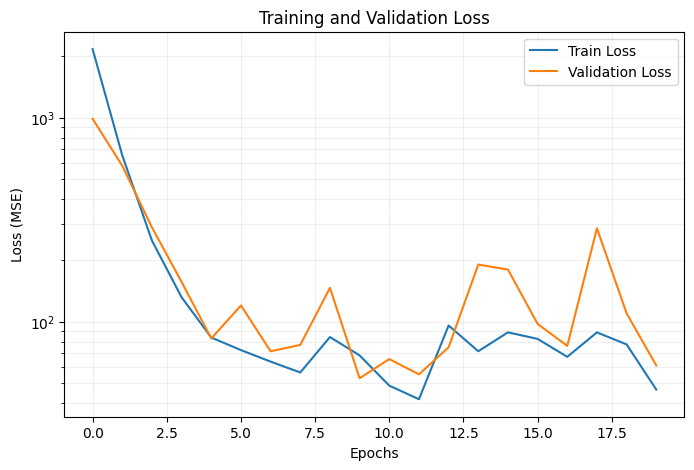

In [74]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.yscale('log') # Skala logarytmiczna jest lepsza dla strat MSE
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.show()

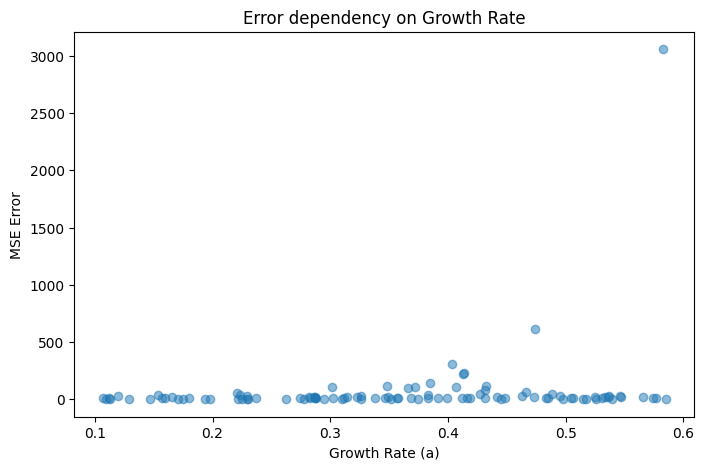

In [76]:
# Pobierz wartości 'growth_rate_a' ze zbioru testowego
rates = test_data['growth_rate_a'].values
errors = np.mean((all_preds - all_targets)**2, axis=1)

plt.figure(figsize=(8, 5))
plt.scatter(rates, errors, alpha=0.5)
plt.xlabel('Growth Rate (a)')
plt.ylabel('MSE Error')
plt.title('Error dependency on Growth Rate')
plt.show()